# Análise complementar - Classificação

O problema de classificação consiste em prever Placement_Status, distinguindo Placed e Not Placed. São examinados o equilíbrio entre as classes e as associações entre atributos e resultado.

In [1]:
import pandas as pd,numpy as np,matplotlib.pyplot as plt,seaborn as sns
from scipy.stats import chi2_contingency,mannwhitneyu
from pathlib import Path
ROOT=Path('..');DATA=ROOT/'data/processed';FIG=ROOT/'reports/figures';TABLE=ROOT/'reports/tables'
FIG.mkdir(parents=True,exist_ok=True);TABLE.mkdir(parents=True,exist_ok=True)
df=pd.read_csv(DATA/'dataset_classification.csv');target='Placement_Status'
counts=df[target].value_counts();display(pd.DataFrame({'n':counts,'percent':100*counts/counts.sum()}))

,n,percent
Placement_Status,,
Placed,39040,78.08
Not Placed,10960,21.92


## 1. Distribuição de classes e alerta de desbalanceamento

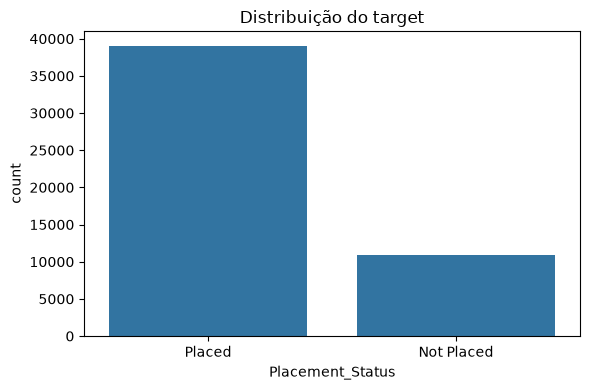

Baseline majoritário de accuracy: 0.7808


In [2]:
fig,ax=plt.subplots(figsize=(6,4));sns.countplot(data=df,x=target,ax=ax,color="C0")
ax.set_title('Distribuição do target');plt.tight_layout();plt.savefig(FIG/'classification_balance.png',dpi=160);plt.show()
print('Baseline majoritário de accuracy:',counts.max()/len(df))

## 2. Relações entre características numéricas e o target

,feature,placed_mean,not_placed_mean,std_mean_diff
14,Employability_Score,220.709495,190.061223,1.226202
13,Interview_Score,80.197336,67.962226,1.016615
8,Internships,4.257787,3.304745,0.961635
4,Programming_Skill,7.433274,6.082391,0.945395
9,Resume_Score,97.697439,90.162318,0.927470
12,Problem_Solving,7.483965,6.074726,0.885551
5,Projects_Completed,9.077741,6.992062,0.874864
3,CGPA,3.147631,2.957903,0.678292
10,Communication_Skills,8.638038,7.715328,0.663313
1,Attendance_Percentage,82.360681,78.021989,0.450493


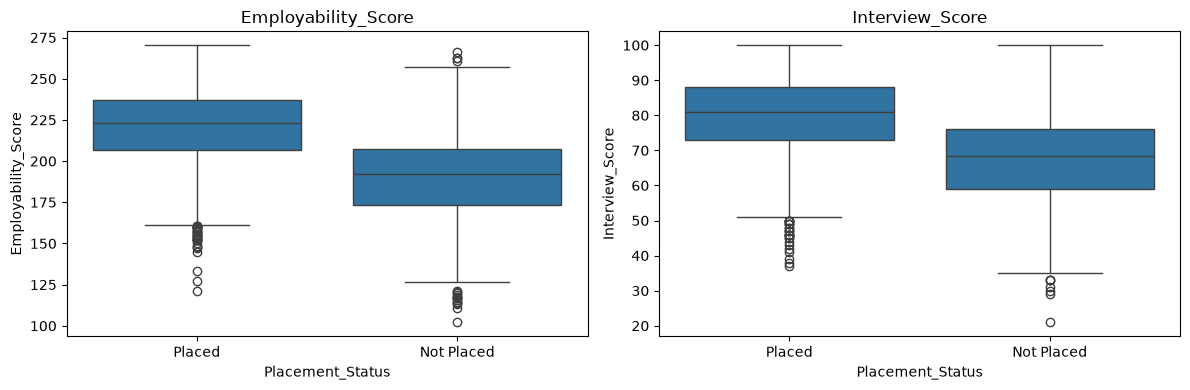

In [3]:
numeric=[c for c in df.select_dtypes(include='number').columns if c!=target]
results=[]
for col in numeric:
    a=df.loc[df[target]=='Placed',col]; b=df.loc[df[target]=='Not Placed',col]
    # descrição de magnitude padronizada da diferença de médias; não implica causalidade
    pooled=np.sqrt((a.var()+b.var())/2)
    effect=(a.mean()-b.mean())/pooled if pooled else np.nan
    results.append((col,a.mean(),b.mean(),effect))
summary=pd.DataFrame(results,columns=['feature','placed_mean','not_placed_mean','std_mean_diff']).sort_values('std_mean_diff',key=lambda x:x.abs(),ascending=False)
display(summary.head(12));summary.to_csv(TABLE/'classification_numeric_comparison.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(12,4))
for ax,col in zip(axs,summary.feature.head(2)):
    sns.boxplot(data=df.sample(min(5000,len(df)),random_state=42),x=target,y=col,ax=ax,color="C0")
    ax.set_title(col)
plt.tight_layout();plt.savefig(FIG/'classification_numeric_boxplots.png',dpi=160);plt.show()

## 3. Associação de variáveis categóricas

In [4]:
cat=[c for c in df.select_dtypes(exclude='number').columns if c!=target]
res=[]
for col in cat:
    matrix=pd.crosstab(df[col],df[target]);chi,p,_,_=chi2_contingency(matrix)
    v=np.sqrt(chi/(matrix.to_numpy().sum()*max(1,min(matrix.shape)-1)))
    res.append((col,chi,p,v))
chi_table=pd.DataFrame(res,columns=['feature','chi2','p','cramers_v']).sort_values('cramers_v',ascending=False)
display(chi_table);chi_table.to_csv(TABLE/'classification_categorical_associations.csv',index=False)

,feature,chi2,p,cramers_v
7,English_Proficiency,4301.386655,0.000000e+00,0.293305
3,Academic_Performance,2709.173224,0.000000e+00,0.232773
2,Major,2130.197958,0.000000e+00,0.206407
5,Leadership_Experience,692.205789,1.481221e-152,0.117661
4,GitHub_Profile,534.096465,3.628667e-118,0.103353
1,University_Year,8.633980,3.457475e-02,0.013141
6,LinkedIn_Profile,0.242870,6.221411e-01,0.002204
0,Gender,0.201193,9.042978e-01,0.002006
